# BloodLink – Data Preprocessing

### Smart Blood Bank Network & Availability Platform

**Project Domain:** Social Network Analysis

**Dataset:** India Blood Bank Directory

**Objective:** To inspect, clean and prepare blood bank records for further analysis.

## Step 1 : Import libraries

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

## Step 2 : Load the dataset

In [ ]:
# Set the project directory
from plotly import data


BASE_DIR = Path.cwd()

# Set the dataset location
file_path = BASE_DIR / "dataset" / "original" / "blood-banks.csv"

# Load the dataset
# Resolve the actual project root (notebook is inside /notebook)
project_root = BASE_DIR.parent if BASE_DIR.name == "notebook" else BASE_DIR

# Update the dataset path to the project root
file_path = project_root / "dataset" / "original" / "blood-banks.csv"

# Confirm the file exists before reading
if not file_path.exists():
    raise FileNotFoundError(f"Dataset not found: {file_path}")


# Display the first five records
data.head()

,state,district,city,name,address,pin,phone,helpline,website,category,components,apheresis,hours,lat,lon
0,andaman-and-nicobar-islands,South Andaman,Port Blair,G.B. Pant Hospital Blood bank,"Atlanta Point, Near Cellular Jail, P.O. Aberde...",744104.0,03192 230628,102,NaN,Government,True,False,24x7,11.67544,92.74734
1,andaman-and-nicobar-islands,South Andaman,Port Blair,I.N.H.S. Dhanvantri,"Ashvini Nagar, Port Blair, Andaman and Nicobar...",744103.0,03192 248759,NaN,NaN,Government,False,False,24x7,11.64969,92.71742
2,andaman-and-nicobar-islands,South Andaman,Port Blair,Pillar Health Centre Blood Bank,"Lamba Line, P.B. 526, P.O. Junglighat, Opposit...",744104.0,"03192 233193, 03192 233993",03192 233193,NaN,Charity,False,False,24x7,11.65323,92.73071
3,andhra-pradesh,Anantapur,Anantapur,"Indian Red Cross Society Blood Bank, District ...","Near JNTU Engeneering College, Sarada Nagar, A...",515002.0,08554 246344,NaN,NaN,Charity,True,False,24x7,14.65494,77.60992
4,andhra-pradesh,Anantapur,Ananthapur,Government General Hospital Blood Bank,"Government General Hospital, Ananthapur",515001.0,08554 275024,NaN,NaN,Government,True,False,24x7,14.67146,77.59668


## Step 3 : Check the shape of the dataset

In [7]:
# Display the number of rows and columns
print("Number of Records:", data.shape[0])
print("Number of Attributes:", data.shape[1])

Number of Records: 2823
Number of Attributes: 15


## Step 4 : Display column information

In [8]:
# Display all column names
print("Dataset Columns:")

for column in data.columns:
    print(column)

Dataset Columns:
state
district
city
name
address
pin
phone
helpline
website
category
components
apheresis
hours
lat
lon


In [9]:
# Display dataset information
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   state       2823 non-null   object 
 1   district    2823 non-null   object 
 2   city        2803 non-null   object 
 3   name        2823 non-null   object 
 4   address     2751 non-null   object 
 5   pin         2628 non-null   float64
 6   phone       2524 non-null   object 
 7   helpline    202 non-null    object 
 8   website     579 non-null    object 
 9   category    2744 non-null   object 
 10  components  2823 non-null   bool   
 11  apheresis   2823 non-null   bool   
 12  hours       2421 non-null   object 
 13  lat         2439 non-null   float64
 14  lon         2439 non-null   float64
dtypes: bool(2), float64(3), object(10)
memory usage: 292.4+ KB


## Step 5 : Check missing values

In [10]:
# Count missing values in each column
missing_values = data.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
state            0
district         0
city            20
name             0
address         72
pin            195
phone          299
helpline      2621
website       2244
category        79
components       0
apheresis        0
hours          402
lat            384
lon            384
dtype: int64


## Step 6 : Calculate missing value percentage

In [11]:
# Calculate missing value percentage
missing_percentage = (data.isnull().sum() / len(data)) * 100

missing_summary = pd.DataFrame({
    "Missing Count": data.isnull().sum(),
    "Missing Percentage": missing_percentage.round(2)
})

display(missing_summary)

,Missing Count,Missing Percentage
state,0,0.00
district,0,0.00
city,20,0.71
name,0,0.00
address,72,2.55
pin,195,6.91
phone,299,10.59
helpline,2621,92.84
website,2244,79.49
category,79,2.80


## Step 7 : Check duplicate records

In [12]:
# Count duplicate records
duplicate_count = data.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 0


## Step 8 : Check unique states and categories

In [13]:
# Count unique states
print("Number of States:", data["state"].nunique())

# Display available states
print("\nAvailable States:")
print(sorted(data["state"].dropna().unique()))

# Display blood bank categories
print("\nBlood Bank Categories:")
print(data["category"].value_counts(dropna=False))

Number of States: 35

Available States:
['andaman-and-nicobar-islands', 'andhra-pradesh', 'arunachal-pradesh', 'assam', 'bihar', 'chandigarh', 'chhattisgarh', 'dadra-and-nagar-haveli-and-daman-and-diu', 'delhi', 'goa', 'gujarat', 'haryana', 'himachal-pradesh', 'jammu-and-kashmir', 'jharkhand', 'karnataka', 'kerala', 'lakshadweep', 'madhya-pradesh', 'maharashtra', 'manipur', 'meghalaya', 'mizoram', 'nagaland', 'odisha', 'puducherry', 'punjab', 'rajasthan', 'sikkim', 'tamil-nadu', 'telangana', 'tripura', 'uttar-pradesh', 'uttarakhand', 'west-bengal']

Blood Bank Categories:
category
Government    1055
Private        999
Charity        690
NaN             79
Name: count, dtype: int64


## Step 9 : Visualize missing values

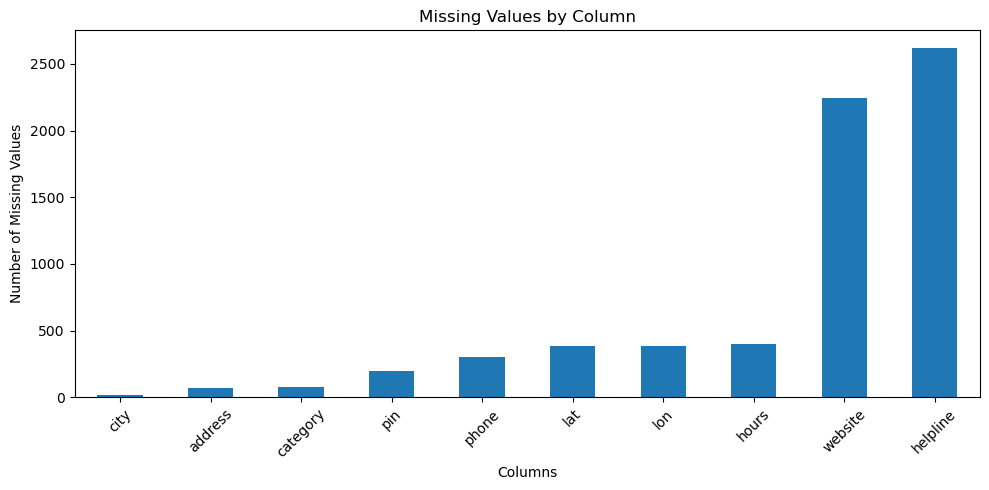

In [14]:
import matplotlib.pyplot as plt

missing_values = data.isnull().sum()

missing_values = missing_values[missing_values > 0]

plt.figure(figsize=(10, 5))

missing_values.sort_values().plot(
    kind="bar",
    title="Missing Values by Column"
)

plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Step 10 : Clean the dataset

In [15]:
# Create a copy of the original dataset
cleaned_data = data.copy()

# Standardize column names
cleaned_data.columns = cleaned_data.columns.str.strip().str.lower()

# Remove extra spaces from text columns
text_columns = cleaned_data.select_dtypes(
    include=["object", "string"]
).columns

for column in text_columns:
    cleaned_data[column] = cleaned_data[column].str.strip()

# Convert empty strings into missing values
cleaned_data = cleaned_data.replace(
    r"^\s*$",
    pd.NA,
    regex=True
)

# Remove duplicate records
cleaned_data = cleaned_data.drop_duplicates()

print("Data cleaning completed.")
print("Original records:", len(data))
print("Cleaned records:", len(cleaned_data))

Data cleaning completed.
Original records: 2823
Cleaned records: 2823


## Step 11 : Validate cleaned data


In [16]:
# Check duplicate records
print("Duplicate records:", cleaned_data.duplicated().sum())

# Check missing values
print("\nMissing values after cleaning:")
display(cleaned_data.isnull().sum())

# Display cleaned dataset
display(cleaned_data.head())

Duplicate records: 0

Missing values after cleaning:


state            0
district         0
city            20
name             0
address         72
pin            195
phone          299
helpline      2621
website       2244
category        79
components       0
apheresis        0
hours          402
lat            384
lon            384
dtype: int64

,state,district,city,name,address,pin,phone,helpline,website,category,components,apheresis,hours,lat,lon
0,andaman-and-nicobar-islands,South Andaman,Port Blair,G.B. Pant Hospital Blood bank,"Atlanta Point, Near Cellular Jail, P.O. Aberde...",744104.0,03192 230628,102,NaN,Government,True,False,24x7,11.67544,92.74734
1,andaman-and-nicobar-islands,South Andaman,Port Blair,I.N.H.S. Dhanvantri,"Ashvini Nagar, Port Blair, Andaman and Nicobar...",744103.0,03192 248759,NaN,NaN,Government,False,False,24x7,11.64969,92.71742
2,andaman-and-nicobar-islands,South Andaman,Port Blair,Pillar Health Centre Blood Bank,"Lamba Line, P.B. 526, P.O. Junglighat, Opposit...",744104.0,"03192 233193, 03192 233993",03192 233193,NaN,Charity,False,False,24x7,11.65323,92.73071
3,andhra-pradesh,Anantapur,Anantapur,"Indian Red Cross Society Blood Bank, District ...","Near JNTU Engeneering College, Sarada Nagar, A...",515002.0,08554 246344,NaN,NaN,Charity,True,False,24x7,14.65494,77.60992
4,andhra-pradesh,Anantapur,Ananthapur,Government General Hospital Blood Bank,"Government General Hospital, Ananthapur",515001.0,08554 275024,NaN,NaN,Government,True,False,24x7,14.67146,77.59668


## Step 12 : Save cleaned dataset

In [19]:
from pathlib import Path

# Create processed folder
cleaned_folder = Path("dataset/cleaned")
cleaned_folder.mkdir(parents=True, exist_ok=True)

# Save cleaned dataset
output_file = cleaned_folder / "blood_banks_cleaned.csv"

cleaned_data.to_csv(output_file, index=False)

print("Cleaned dataset saved successfully!")
print("Location:", output_file)

Cleaned dataset saved successfully!
Location: dataset\cleaned\blood_banks_cleaned.csv


In [20]:
import os

print("Current Working Directory:")
print(os.getcwd())

print("\nFiles and folders:")
print(os.listdir())

Current Working Directory:
c:\Users\NITHYA\OneDrive\Desktop\BloodLink_SNA\notebook

Files and folders:
['01_data_preprocessing.ipynb', 'dataset']
